<a href="https://colab.research.google.com/github/castr1x/ML_an.nykoliuk_3-12/blob/main/%D0%9B%D0%A0_2_2_%D0%9C%D0%9D_%D0%9D%D0%B8%D0%BA%D0%BE%D0%BB%D1%8E%D0%BA%D0%B0_%D0%A4%D0%86%D0%A2_3_12.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [6]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [7]:
# Install dependencies as needed:
# pip install kagglehub[pandas-datasets]
import kagglehub
from kagglehub import KaggleDatasetAdapter

# Set the path to the file you'd like to load
file_path = "titanic.csv"

# Load the latest version
df = kagglehub.load_dataset(
  KaggleDatasetAdapter.PANDAS,
  "mahmoudshogaa/titanic-dataset",
  file_path,
  # Provide any additional arguments like
  # sql_query or pandas_kwargs. See the
  # documenation for more information:
  # https://github.com/Kaggle/kagglehub/blob/main/README.md#kaggledatasetadapterpandas
)
df.head()

/tmp/ipykernel_638/1457548319.py:10: DeprecationWarning: Use dataset_load() instead of load_dataset(). load_dataset() will be removed in a future version.
  df = kagglehub.load_dataset(


Using Colab cache for faster access to the 'titanic-dataset' dataset.


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


## Про набір даних (About Dataset)

Цей датасет містить дані про 891 пассажира титаніка який затонув

Цей набір даних містить такі колонки:

* **PassengerId**: Унікальний ідентифікатор кожного пасажира.
* **Survived**: Вказує, вижив пасажир (`1`) чи не вижив (`0`).
* **Pclass** *(Клас квитка)*: Показник соціально-економічного статусу, де `1` — найвищий клас, а `3` — найнижчий.
* **Name**: Ім'я пасажира.
* **Sex**: Стать пасажира.
* **Age**: Вік пасажира. *(Примітка: у цій колонці можуть бути пропущені значення).*
* **SibSp**: Кількість братів/сестер або чоловіка/дружини пасажира на борту "Титаніка".
* **Parch**: Кількість батьків або дітей пасажира на борту "Титаніка".
* **Ticket**: Номер квитка.
* **Fare**: Сума грошей, яку пасажир заплатив за квиток.
* **Embarked**: Порт посадки пасажира на корабель. Зазвичай містить три значення: `C` (Шербур / Cherbourg), `Q` (Квінстаун / Queenstown) та `S` (Саутгемптон / Southampton).


In [8]:
df.describe()

,PassengerId,Survived,Pclass,Age,SibSp,Parch,Fare
count,891.000000,891.000000,891.000000,714.000000,891.000000,891.000000,891.000000
mean,446.000000,0.383838,2.308642,29.699118,0.523008,0.381594,32.204208
std,257.353842,0.486592,0.836071,14.526497,1.102743,0.806057,49.693429
min,1.000000,0.000000,1.000000,0.420000,0.000000,0.000000,0.000000
25%,223.500000,0.000000,2.000000,20.125000,0.000000,0.000000,7.910400
50%,446.000000,0.000000,3.000000,28.000000,0.000000,0.000000,14.454200
75%,668.500000,1.000000,3.000000,38.000000,1.000000,0.000000,31.000000
max,891.000000,1.000000,3.000000,80.000000,8.000000,6.000000,512.329200


In [9]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    object 
 4   Sex          891 non-null    object 
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    object 
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    object 
 11  Embarked     889 non-null    object 
dtypes: float64(2), int64(5), object(5)
memory usage: 83.7+ KB


# Стовпчик Cabin містить NaN значення, проте не містить корисних даних для подальшого аналізу, тому видаляємо його

In [10]:
df.drop(columns='Cabin',inplace=True)

In [11]:
for i in df.columns:
    print(i, df[f'{i}'].isna().sum(),sep= ' ---> ')

PassengerId ---> 0
Survived ---> 0
Pclass ---> 0
Name ---> 0
Sex ---> 0
Age ---> 177
SibSp ---> 0
Parch ---> 0
Ticket ---> 0
Fare ---> 0
Embarked ---> 2


# В цьому наборі даних ми маємо NaN Значення по стовбцям Age та Embarked

-- Для віку заповнимо пропуски модою, для порту посадки також

In [12]:
nan_cols = ['Embarked','Age']

for i in nan_cols:
    df[i] = df[i].fillna(df[i].mode()[0])

# Ми заповнили пропуски

In [13]:
df.isna().sum()

,0
PassengerId,0
Survived,0
Pclass,0
Name,0
Sex,0
Age,0
SibSp,0
Parch,0
Ticket,0
Fare,0


### Далі сформуємо датасет з цікавлячими нас ознаками

In [14]:
main = df[['PassengerId','Survived','Sex','Age','Fare', 'Pclass','SibSp','Parch']]

### Знайдемо ще одну додаткову ознаку

In [15]:
def is_single(data):
    if data['SibSp'] + data['Parch']>0:
        return 0
    else:
        return 1


In [16]:
main['is_single'] = main.apply(is_single, axis = 1)

/tmp/ipykernel_638/3451982411.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  main['is_single'] = main.apply(is_single, axis = 1)


In [17]:
main.head()

,PassengerId,Survived,Sex,Age,Fare,Pclass,SibSp,Parch,is_single
0,1,0,male,22.0,7.2500,3,1,0,0
1,2,1,female,38.0,71.2833,1,1,0,0
2,3,1,female,26.0,7.9250,3,0,0,1
3,4,1,female,35.0,53.1000,1,1,0,0
4,5,0,male,35.0,8.0500,3,0,0,1


### Ми маємо дані про сімейний стан пасажирів титаніка, а саме:
* *SibSp* - кількість братів/сестер/чоловіка чи дружини на борту
* *Parch* - кількість батьків або дітей пасажира на борту

> Відповідно ми можемо сказати, що якщо сума цих ознак дорівнює нулю, то пассажир не мав родичів на борту і скоріш за все відправився сам

### Тепер розглянемо розподіл виживаності пасажирів у розрізі ознак

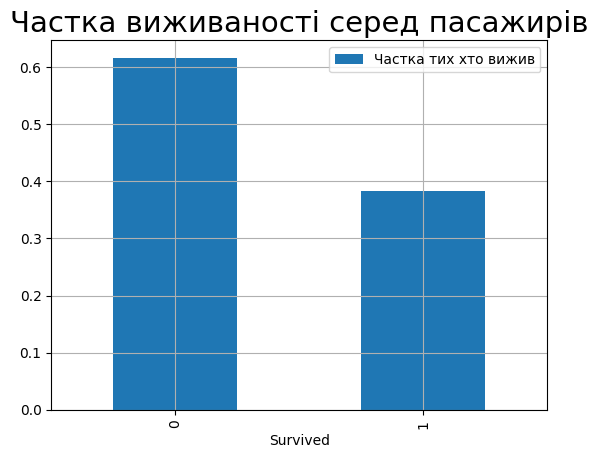

In [18]:
global_survived = main['Survived'].value_counts(normalize=True).reset_index(name='Частка тих хто вижив')
global_survived.plot(kind ='bar', x = 'Survived')
plt.title('Частка виживаності серед пасажирів',fontdict={'fontsize':21})
plt.grid(True)

#### На графіку видно, що серед всіх пасажирів вижили близько **38%**

Text(0.5, 1.0, 'Розподіл виживаності за статтю')

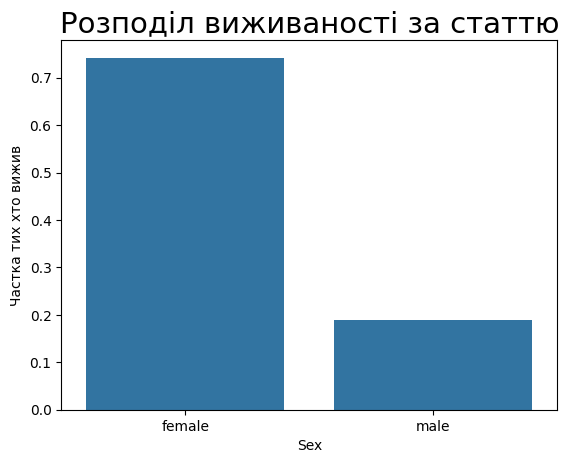

In [19]:
by_sex = main.groupby('Sex')['Survived'].mean().reset_index(name='Частка тих хто вижив')
sns.barplot(by_sex, x = 'Sex', y = 'Частка тих хто вижив')
plt.title('Розподіл виживаності за статтю', fontdict={'fontsize':21})

#### На графіку бачимо наступне:
* Частка *****Жінок***** що вижили серед всіх пасажирів становить близько *****75%*****
* Частка *****Чоловіків***** що вижили серед всіх пасажирів становить близько *****19%*****

In [20]:
main['Sex'] = main['Sex'].map({'male':0, 'female':1})

/tmp/ipykernel_638/2869122607.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  main['Sex'] = main['Sex'].map({'male':0, 'female':1})


In [28]:
by_pclass = main.groupby('Pclass')['Survived'].mean().reset_index(name='Частка тих хто виижив').sort_values(by='Pclass')

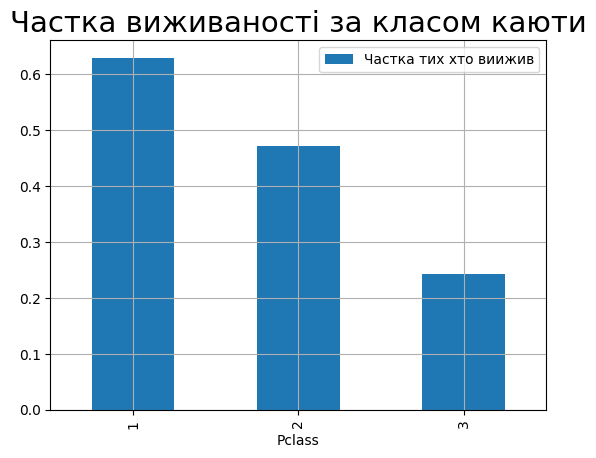

In [31]:
by_pclass.plot(kind='bar', x = 'Pclass')
plt.title('Частка виживаності за класом каюти', fontdict={'fontsize':21})
plt.grid(True)

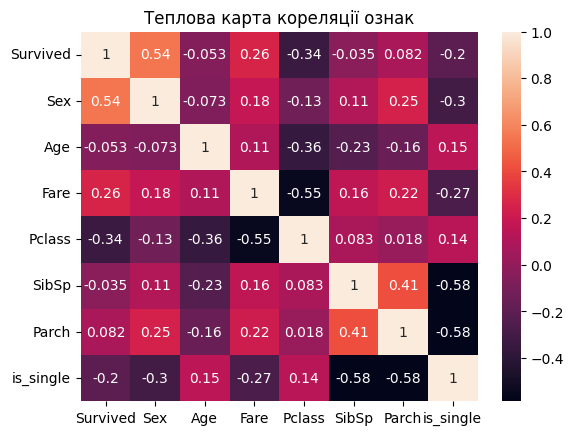

In [30]:
sns.heatmap(main[main.columns[1::]].corr(),annot=True)
plt.title('Теплова карта кореляції ознак')
plt.show()

#### Найсильніше на виживаність впливали стать пасажира та клас його каюти: жінки мали значно вищі шанси на порятунок. Також вища вартість квитка та 1-й клас каюти суттєво збільшували імовірність вижити.

## Отже, опинившись на титаніку, зважаючи на всі фактори та статистику виживаності я б хотів бути багатою жінкою, що подорожує першим класом з родиною

# Завдання 2

In [36]:
# Install dependencies as needed:
# pip install kagglehub[pandas-datasets]
import kagglehub
from kagglehub import KaggleDatasetAdapter

# Set the path to the file you'd like to load
file_path = "bestsellers with categories.csv"

# Load the latest version
df = kagglehub.load_dataset(
  KaggleDatasetAdapter.PANDAS,
  "sootersaalu/amazon-top-50-bestselling-books-2009-2019",
  file_path,
  # Provide any additional arguments like
  # sql_query or pandas_kwargs. See the
  # documenation for more information:
  # https://github.com/Kaggle/kagglehub/blob/main/README.md#kaggledatasetadapterpandas
)
df.head()

/tmp/ipykernel_638/3994631302.py:10: DeprecationWarning: Use dataset_load() instead of load_dataset(). load_dataset() will be removed in a future version.
  df = kagglehub.load_dataset(


Using Colab cache for faster access to the 'amazon-top-50-bestselling-books-2009-2019' dataset.


,Name,Author,User Rating,Reviews,Price,Year,Genre
0,10-Day Green Smoothie Cleanse,JJ Smith,4.7,17350,8,2016,Non Fiction
1,11/22/63: A Novel,Stephen King,4.6,2052,22,2011,Fiction
2,12 Rules for Life: An Antidote to Chaos,Jordan B. Peterson,4.7,18979,15,2018,Non Fiction
3,1984 (Signet Classics),George Orwell,4.7,21424,6,2017,Fiction
4,"5,000 Awesome Facts (About Everything!) (Natio...",National Geographic Kids,4.8,7665,12,2019,Non Fiction


## Про цей датасет (About this dataset)

Набір даних про **50 найпродаваніших книг-бестселерів на Amazon** за період з **2009 по 2019 рік**. Датасет містить інформацію про 550 книг, які за допомогою платформи *Goodreads* було розподілено на художню (*fiction*) та документальну/науково-популярну (*non-fiction*) літературу.

### Опис колонок:

* **Name**: Назва книги.
* **Author**: Автор книги.
* **User Rating**: Рейтинг книги серед користувачів Amazon (за 5-бальною шкалою).
* **Reviews**: Кількість текстових відгуків та рецензій на Amazon.
* **Price**: Вартість книги у доларах США (станом на 13.10.2020).
* **Year**: Рік (або роки), у які книга входила до рейтингу бестселерів.
* **Genre**: Жанр літератури (`Fiction` — художжня або `Non Fiction` — нон-фікшн / документальна).

In [38]:
df.shape

(550, 7)

In [40]:
df.duplicated().sum()

np.int64(0)

In [42]:
for i in df.columns:
  print(i, df[i].duplicated().sum(),sep = '---> ')

Name---> 199
Author---> 302
User Rating---> 536
Reviews---> 204
Price---> 510
Year---> 539
Genre---> 548


#### Доцільно буде видалити дублікати лише за назвою, оскільки можна допустити, що інші ознаки повторюватимуться

In [43]:
cleaned = df.drop_duplicates(subset='Name')

In [46]:
cleaned.shape

(351, 7)

In [50]:
cleaned.columns = [i.lower() for i in list(cleaned.columns)]

In [52]:
cleaned.head()

,name,author,user rating,reviews,price,year,genre
0,10-Day Green Smoothie Cleanse,JJ Smith,4.7,17350,8,2016,Non Fiction
1,11/22/63: A Novel,Stephen King,4.6,2052,22,2011,Fiction
2,12 Rules for Life: An Antidote to Chaos,Jordan B. Peterson,4.7,18979,15,2018,Non Fiction
3,1984 (Signet Classics),George Orwell,4.7,21424,6,2017,Fiction
4,"5,000 Awesome Facts (About Everything!) (Natio...",National Geographic Kids,4.8,7665,12,2019,Non Fiction


In [56]:
cleaned.info()

<class 'pandas.core.frame.DataFrame'>
Index: 351 entries, 0 to 546
Data columns (total 7 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   name         351 non-null    object 
 1   author       351 non-null    object 
 2   user rating  351 non-null    float64
 3   reviews      351 non-null    int64  
 4   price        351 non-null    int64  
 5   year         351 non-null    int64  
 6   genre        351 non-null    object 
dtypes: float64(1), int64(3), object(3)
memory usage: 21.9+ KB


In [57]:
cleaned.isna().sum()

,0
name,0
author,0
user rating,0
reviews,0
price,0
year,0
genre,0


In [59]:
cleaned.genre.value_counts()

,count
genre,
Non Fiction,191
Fiction,160


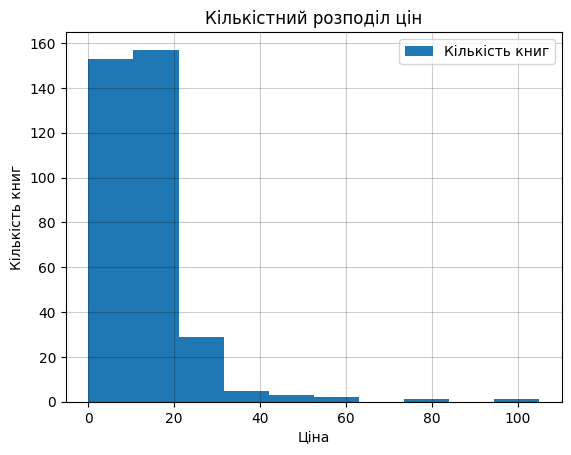

In [71]:
cleaned.price.plot(kind = 'hist',label = 'Кількість книг')
plt.xlabel('Ціна')
plt.ylabel('Кількість книг')
plt.title('Кількістний розподіл цін')
plt.grid(True,alpha = 0.2, color = 'black')
plt.legend()
plt.show()


In [79]:
des_price = cleaned['price'].describe()
des_price

,price
count,351.000000
mean,13.076923
std,10.050860
min,0.000000
25%,8.000000
50%,12.000000
75%,16.000000
max,105.000000


In [85]:
print(f"Мінімальна ціна - {des_price[3]}\nМаксимальна ціна - {des_price[-1]}\nМедіанна ціна - {des_price[-3]}")

Мінімальна ціна - 0.0
Максимальна ціна - 105.0
Медіанна ціна - 12.0


/tmp/ipykernel_638/780484743.py:1: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  print(f"Мінімальна ціна - {des_price[3]}\nМаксимальна ціна - {des_price[-1]}\nМедіанна ціна - {des_price[-3]}")


In [92]:
print(
      f'''
      Найбільший рейтинг серед всіх - {cleaned['user rating'].max()}
      Книг з таким рейтингом - {cleaned[cleaned['user rating']==4.9]['name'].count()}
      ''')


      Найбільший рейтинг серед всіх - 4.9
      Книг з таким рейтингом - 28
      


In [112]:
print(
    f'''
    Найбільша кількість відгуків - {cleaned['reviews'].max()}
    У книиги - {cleaned[cleaned['reviews']==cleaned['reviews'].max()]['name'].iloc[0]}

     '''
)


    Найбільша кількість відгуків - 87841
    у книиги - Where the Crawdads Sing

     


In [121]:
answer = cleaned[cleaned['year']==2015].set_index('name')['price'].idxmax()

print(
    f'''
Найдорожча книга серед тих, що потрапили в топ 50 у 2015 році - {answer}
     '''

)



Найдорожча книга серед тих, що потрапили в топ 50 у 2015 році - Go Set a Watchman: A Novel
     


In [130]:
answer = cleaned[(cleaned['year']==2010)&(cleaned['genre']=='Fiction')]['name'].count()

print(
    f'''
В топ 50 книг в 2010 році потрапили {answer} книг із жанру Fiction
     '''
)


В топ 50 книг в 2010 році потрапили 17 книг із жанру Fiction
     


In [136]:
answer = cleaned[(cleaned['user rating']==4.9) & (cleaned['year'].isin([2010,2011]))]['name'].count()

print(
    f'''
У проміжок з 2010 по 2011 роки з рейтингом 4,9 в топ 50 потрапила {answer} книга
    '''
)


У проміжок з 2010 по 2011 роки з рейтингом 4,9 в топ 50 потрапила 1 книга
    


In [140]:
cleaned[(cleaned['price']<8)&(cleaned['year']==2015)].sort_values(by = 'price').tail(1)

,name,author,user rating,reviews,price,year,genre
253,Old School (Diary of a Wimpy Kid #10),Jeff Kinney,4.8,6169,7,2015,Fiction


In [141]:
cleaned.groupby('genre')['price'].agg([np.min,np.max])

/tmp/ipykernel_638/382588552.py:1: FutureWarning: The provided callable <function min at 0x7baaec99d300> is currently using SeriesGroupBy.min. In a future version of pandas, the provided callable will be used directly. To keep current behavior pass the string "min" instead.
  cleaned.groupby('genre')['price'].agg([np.min,np.max])
/tmp/ipykernel_638/382588552.py:1: FutureWarning: The provided callable <function max at 0x7baaec99d1c0> is currently using SeriesGroupBy.max. In a future version of pandas, the provided callable will be used directly. To keep current behavior pass the string "max" instead.
  cleaned.groupby('genre')['price'].agg([np.min,np.max])


,min,max
genre,,
Fiction,0,82
Non Fiction,0,105


In [149]:
book_by_author = cleaned.author.value_counts()
book_by_author

,count
author,
Jeff Kinney,12
Rick Riordan,10
Stephenie Meyer,7
Dav Pilkey,6
Bill O'Reilly,6
...,...
Cheryl Strayed,1
Ken Follett,1
Geneen Roth,1


In [154]:
print(
    f'''
Найбільше книг написав - {book_by_author.idxmax()}, а саме {book_by_author.iloc[0]} книг
    '''
)


Найбільше книг написав - Jeff Kinney, а саме 12 книг
    


In [164]:
rating_by_author = cleaned.groupby('author')['user rating'].mean().sort_values()

print(
    f'''
Найменший середній рейтинг у автора {answer.idxmin()}, він складає {answer.iloc[0]}
    '''
)


Найменший середній рейтинг у автора Donna Tartt, він складає 3.9
    


In [169]:
result = pd.concat([rating_by_author,book_by_author],axis = 1)

In [173]:
by_book_and_rating = result.sort_values(by = ['count','user rating'])

In [174]:
by_book_and_rating

,user rating,count
author,,
Donna Tartt,3.900000,1
Gallup,4.000000,1
Gillian Flynn,4.000000,1
Muriel Barbery,4.000000,1
Ian K. Smith M.D.,4.100000,1
...,...,...
Bill O'Reilly,4.633333,6
Dav Pilkey,4.900000,6
Stephenie Meyer,4.657143,7


In [193]:
print(f'Перший в списку - {by_book_and_rating.reset_index().iloc[0][0]}')

Перший в списку - Donna Tartt


/tmp/ipykernel_638/2091286578.py:1: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  print(f'Перший в списку - {by_book_and_rating.reset_index().iloc[0][0]}')
